# Spotify Music Analysis

This exploratory data analysis examines the Spotify Tracks Dataset, which contains 114,000 tracks across 114 genres. It asks how popularity varies, how audio-feature averages differ across genres, how audio features relate to one another, whether audio features are associated with popularity, and whether popularity differs between explicit and non-explicit tracks. The findings describe this dataset and do not establish causes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Spotify Music Analysis")

Spotify Music Analysis


## 1. Dataset overview and loading

Load the Kaggle CSV and check its dimensions and fields before exploring data quality and track-level patterns. The notebook expects the downloaded file at `data/dataset.csv`.

In [2]:
df = pd.read_csv("../data/dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 2. Initial data inspection and quality checks

Inspect a sample of rows, dataset size and columns, missing values, duplicate rows, and the `Unnamed: 0` field. The goal is to identify data-quality considerations before interpreting the later summaries.

In [3]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
df.shape

(114000, 21)

In [5]:
df.columns.tolist()

['Unnamed: 0',
 'track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

In [6]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [9]:
df[df.isnull().any(axis=1)]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [10]:
df["Unnamed: 0"].head()

0    0
1    1
2    2
3    3
4    4
Name: Unnamed: 0, dtype: int64

In [11]:
df["Unnamed: 0"].nunique()

114000

### Initial inspection findings

The dataset has 114,000 rows and 21 columns, with 1,000 tracks per genre. There is one missing value in each of `artists`, `album_name`, and `track_name`; all three belong to the same row. No exact duplicate rows were found. `Unnamed: 0` contains 114,000 unique values and may be a redundant original index. These are initial checks only: no complete cleaning has been performed, and the missing values and index column have not yet been handled.

## 3. Popularity distribution and zero-popularity tracks

The summary below reports a mean of about 33.24, a median of 35, a standard deviation of about 22.31, and a range from 0 to 100. The histogram shows how scores are distributed; it describes the data but does not explain what causes a track to receive a particular score.

In [12]:
df["popularity"].describe()

count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

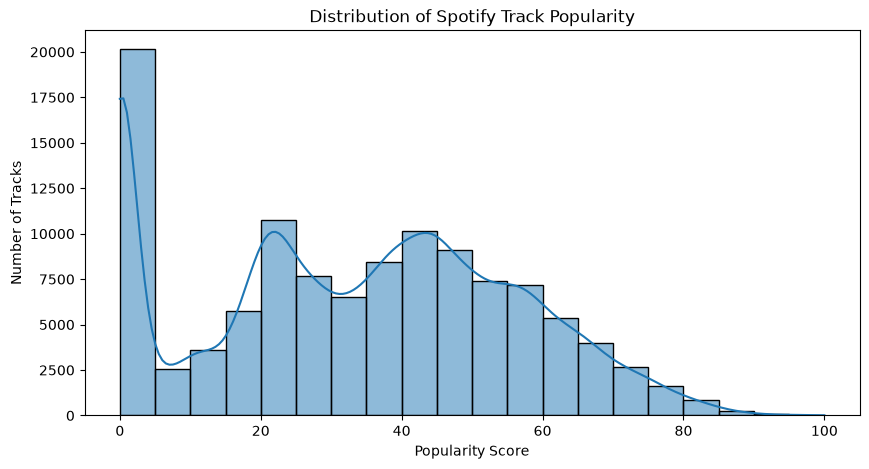

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="popularity", bins=20, kde=True)

plt.title("Distribution of Spotify Track Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Tracks")

plt.show()

### Tracks with zero popularity

There are 16,020 tracks with a popularity score of zero (14.05% of the dataset). The largest genre percentages are Jazz (68.1%), Iranian (65.6%), and Romance (63.6%). The following cells calculate the count and show the genre-level results.

**Limitation:** a zero score does not establish that a track has never been listened to, and these data do not explain why a score is zero.

In [14]:
zero_popularity = df[df["popularity"] == 0]

print("Tracks with zero popularity:", len(zero_popularity))

print(
    "Percentage of dataset:",
    round((len(zero_popularity) / len(df)) * 100, 2),
    "%"
)

Tracks with zero popularity: 16020
Percentage of dataset: 14.05 %


In [15]:
zero_popularity[["track_name", "artists", "track_genre", "popularity"]].head(10)

,track_name,artists,track_genre,popularity
23,93 Million Miles,Jason Mraz,acoustic,0
24,Unlonely,Jason Mraz,acoustic,0
26,Winter Wonderland,Jason Mraz,acoustic,0
27,If It Kills Me,Jason Mraz,acoustic,0
28,Winter Wonderland,Jason Mraz,acoustic,0
29,Winter Wonderland,Jason Mraz,acoustic,0
30,Winter Wonderland,Jason Mraz,acoustic,0
31,Winter Wonderland,Jason Mraz,acoustic,0
32,All I Want For Christmas Is A Real Good Tan,Chord Overstreet,acoustic,0
33,Party of One,Brandi Carlile;Sam Smith,acoustic,0


In [16]:
zero_popularity["track_genre"].value_counts().head(10)

track_genre
jazz           681
iranian        656
romance        636
soul           611
latin          588
country        587
rock           525
dance          490
alternative    485
house          403
Name: count, dtype: int64

In [17]:
zero_popularity_by_genre = (
    df.groupby("track_genre")["popularity"]
    .apply(lambda x: (x == 0).mean() * 100)
    .sort_values(ascending=False)
)



In [18]:
zero_popularity_by_genre.head(10)

track_genre
jazz           68.1
iranian        65.6
romance        63.6
soul           61.1
latin          58.8
country        58.7
rock           52.5
dance          49.0
alternative    48.5
house          40.3
Name: popularity, dtype: float64

In [19]:
df["track_genre"].value_counts().head(10)

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64

## 4. Energy by genre

How does average energy vary across genres? These cells compare the highest and lowest mean energy groups. Death metal had the highest average (0.931), while classical had the lowest (0.190). These are genre averages within this dataset, not descriptions of every track in those genres.

In [20]:
df.groupby("track_genre")["energy"].mean().sort_values(ascending=False).head(10)

track_genre
death-metal      0.931470
grindcore        0.924201
metalcore        0.914485
happy            0.910971
hardstyle        0.901246
drum-and-bass    0.876635
black-metal      0.874897
heavy-metal      0.874003
party            0.871237
j-idol           0.868677
Name: energy, dtype: float64

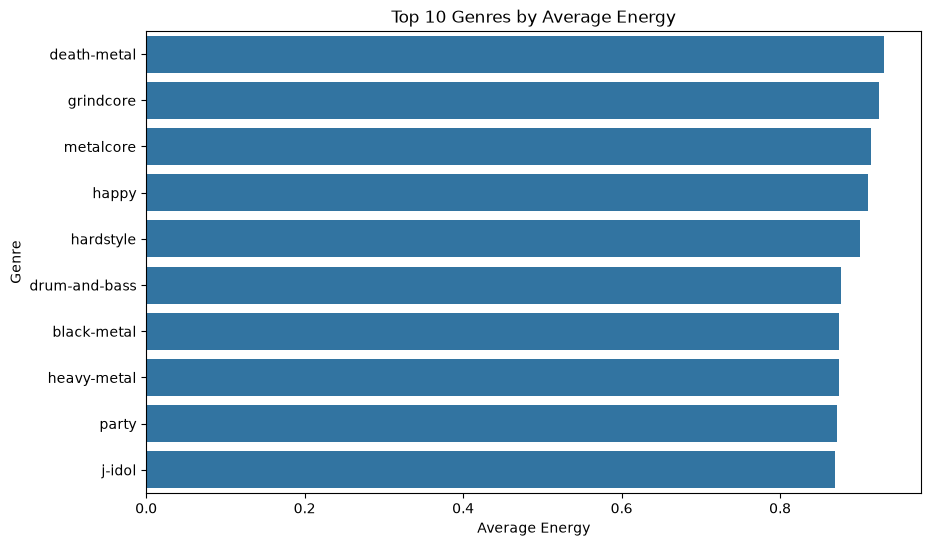

In [21]:
top_energy_genres = (
    df.groupby("track_genre")["energy"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_energy_genres.values,
    y=top_energy_genres.index
)

plt.title("Top 10 Genres by Average Energy")
plt.xlabel("Average Energy")
plt.ylabel("Genre")

plt.show()

In [22]:
bottom_energy_genres = (
    df.groupby("track_genre")["energy"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

bottom_energy_genres

track_genre
classical    0.189827
new-age      0.214501
ambient      0.237162
romance      0.294304
disney       0.302519
opera        0.317054
piano        0.320103
guitar       0.324999
sleep        0.342072
jazz         0.352954
Name: energy, dtype: float64

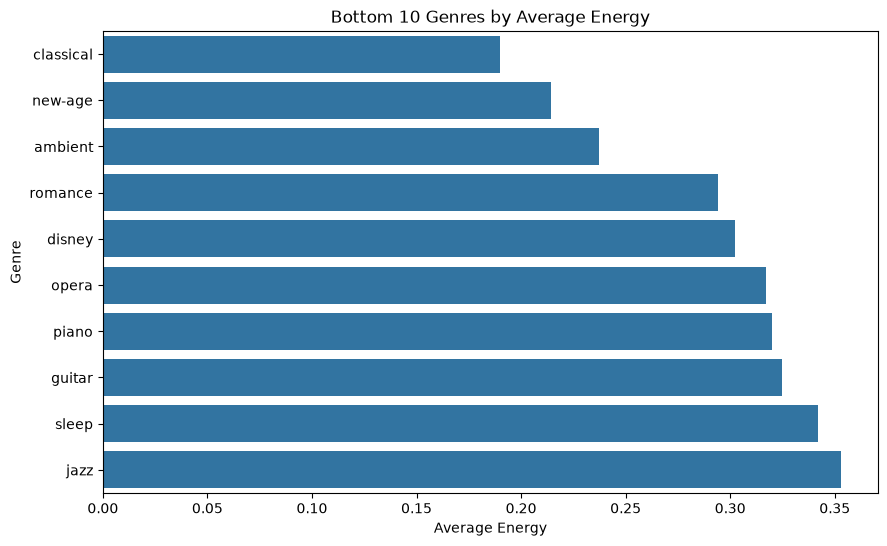

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=bottom_energy_genres.values,
    y=bottom_energy_genres.index
)

plt.title("Bottom 10 Genres by Average Energy")
plt.xlabel("Average Energy")
plt.ylabel("Genre")

plt.show()


## 5. Danceability by genre

How does average danceability vary by genre? The highest five genre averages are Kids (0.779), Chicago-house (0.766), Reggaeton (0.759), Latino (0.757), and Reggae (0.745). The lowest five are Sleep (0.168), Grindcore (0.272), Black metal (0.296), Iranian (0.301), and Opera (0.314).

**Observation:** Grindcore and black metal are among the highest-energy genres but among the lowest in danceability; death metal also has low average danceability despite its high average energy. These averages motivate a track-level comparison but do not establish an individual-track relationship.

In [24]:
top_danceability_genres = (
    df.groupby("track_genre")["danceability"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_danceability_genres

track_genre
kids              0.778906
chicago-house     0.766176
reggaeton         0.758521
latino            0.757057
reggae            0.745331
hip-hop           0.736154
dancehall         0.734169
minimal-techno    0.729395
detroit-techno    0.722568
latin             0.721902
Name: danceability, dtype: float64

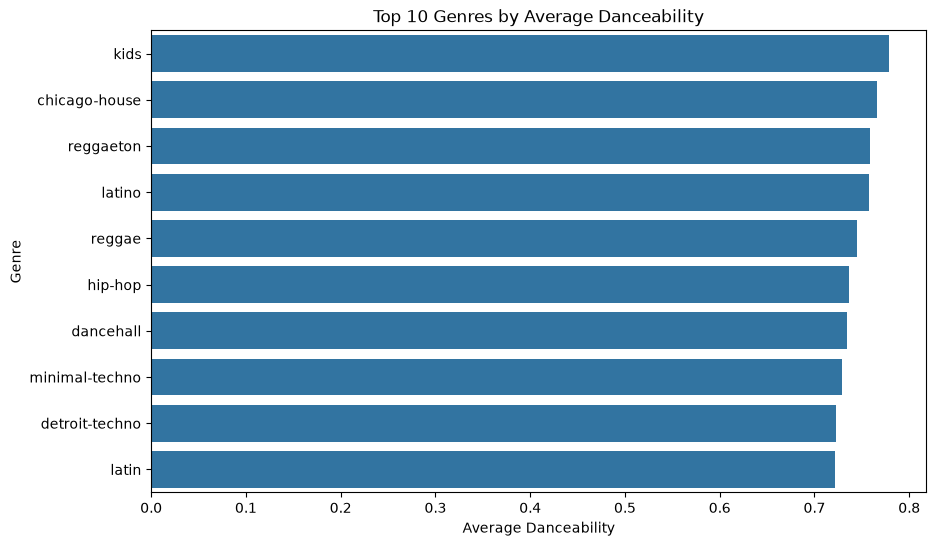

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_danceability_genres.values,
    y=top_danceability_genres.index
)

plt.title("Top 10 Genres by Average Danceability")
plt.xlabel("Average Danceability")
plt.ylabel("Genre")

plt.show()

In [26]:
bottom_danceability_genres = (
    df.groupby("track_genre")["danceability"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

bottom_danceability_genres

track_genre
sleep          0.167923
grindcore      0.271854
black-metal    0.296411
iranian        0.300686
opera          0.313563
new-age        0.348455
ambient        0.367867
death-metal    0.368411
classical      0.381923
world-music    0.414572
Name: danceability, dtype: float64

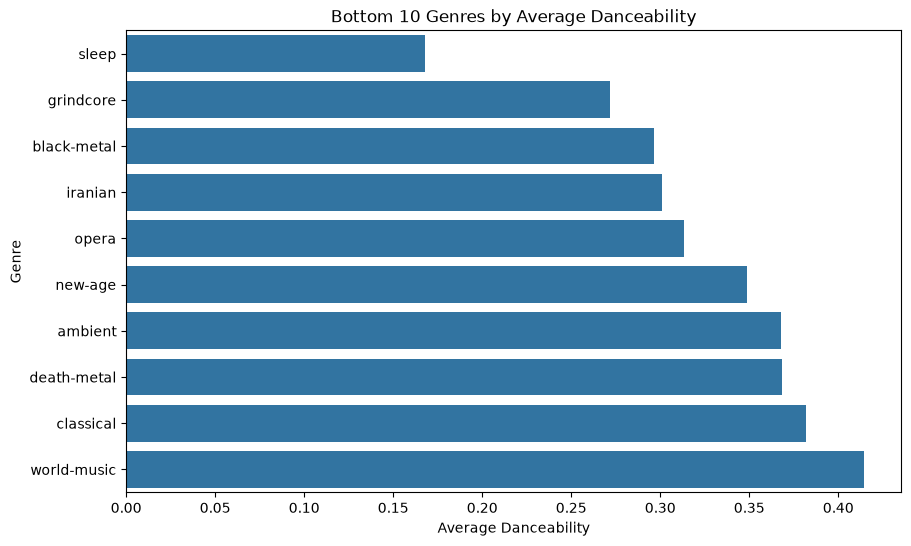

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=bottom_danceability_genres.values,
    y=bottom_danceability_genres.index
)

plt.title("Bottom 10 Genres by Average Danceability")
plt.xlabel("Average Danceability")
plt.ylabel("Genre")

plt.show()

## 6. Acousticness by genre

How does average acousticness vary by genre? The highest five averages are Classical (0.920), Romance (0.869), Tango (0.846), New-age (0.824), and Opera (0.795). The lowest five are Death metal (0.007), Grindcore (0.009), Metalcore (0.010), Heavy metal (0.015), and Drum and bass (0.026). These are descriptive group averages for this dataset.

In [28]:
top_acousticness_genres = (
    df.groupby("track_genre")["acousticness"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_acousticness_genres

track_genre
classical    0.920049
romance      0.869495
tango        0.846209
new-age      0.824022
opera        0.794931
ambient      0.776790
guitar       0.773053
disney       0.742892
comedy       0.726476
jazz         0.715816
Name: acousticness, dtype: float64

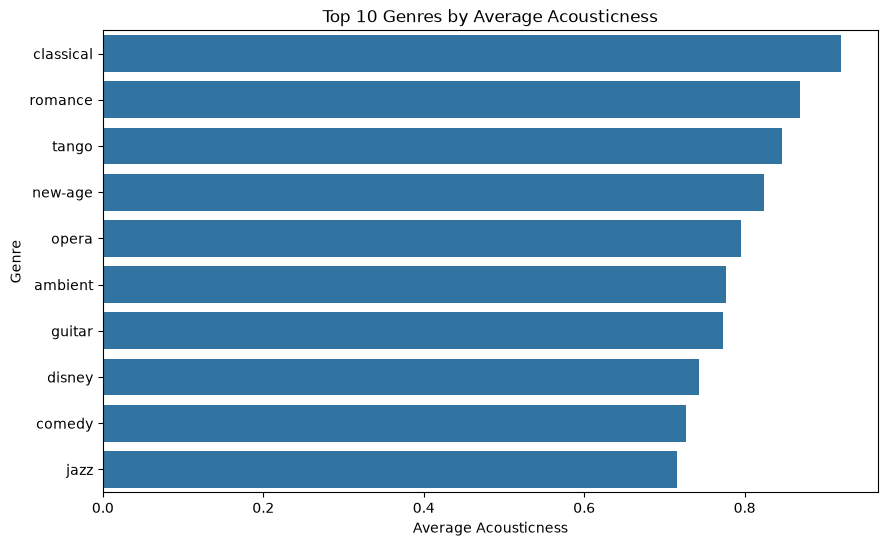

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_acousticness_genres.values,
    y=top_acousticness_genres.index
)

plt.title("Top 10 Genres by Average Acousticness")
plt.xlabel("Average Acousticness")
plt.ylabel("Genre")

plt.show()

In [30]:
bottom_acousticness_genres = (
    df.groupby("track_genre")["acousticness"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

bottom_acousticness_genres

track_genre
death-metal      0.006696
grindcore        0.008698
metalcore        0.010286
heavy-metal      0.014968
drum-and-bass    0.025931
black-metal      0.027056
breakbeat        0.031410
chicago-house    0.035310
trance           0.035870
industrial       0.036728
Name: acousticness, dtype: float64

## 7. Valence by genre

How does average valence vary by genre? Salsa had the highest average valence (0.815), while sleep had the lowest (0.058). The cells compare the highest and lowest genre averages.

In [31]:
top_valence_genres = (
    df.groupby("track_genre")["valence"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_valence_genres

track_genre
salsa         0.814838
forro         0.760693
rockabilly    0.726951
afrobeat      0.698619
ska           0.696720
children      0.694287
samba         0.693409
pagode        0.687978
party         0.681235
kids          0.680864
Name: valence, dtype: float64

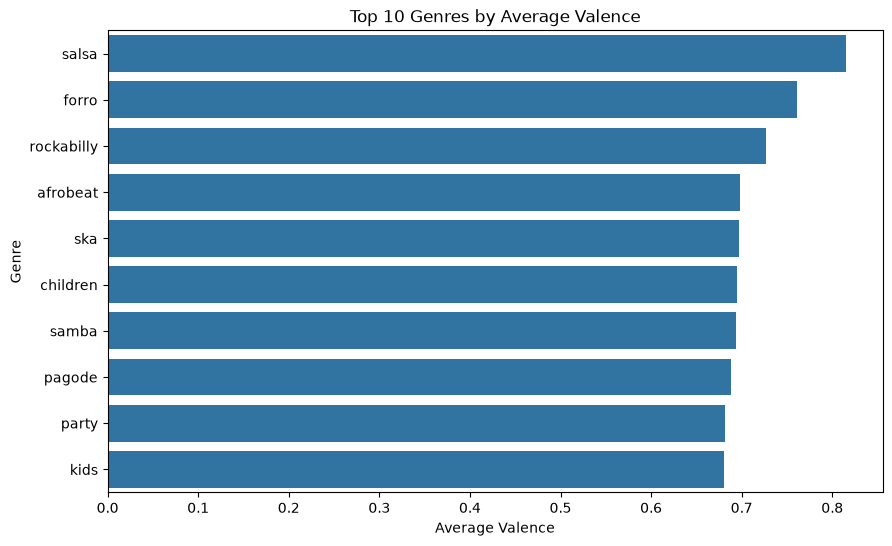

In [32]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_valence_genres.values,
    y=top_valence_genres.index
)

plt.title("Top 10 Genres by Average Valence")
plt.xlabel("Average Valence")
plt.ylabel("Genre")

plt.show()

In [33]:
bottom_valence_genres = (
    df.groupby("track_genre")["valence"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
)

bottom_valence_genres

track_genre
sleep          0.058188
iranian        0.153536
ambient        0.167498
new-age        0.183167
black-metal    0.191736
opera          0.215225
grindcore      0.216434
death-metal    0.247611
world-music    0.250295
dubstep        0.271709
Name: valence, dtype: float64

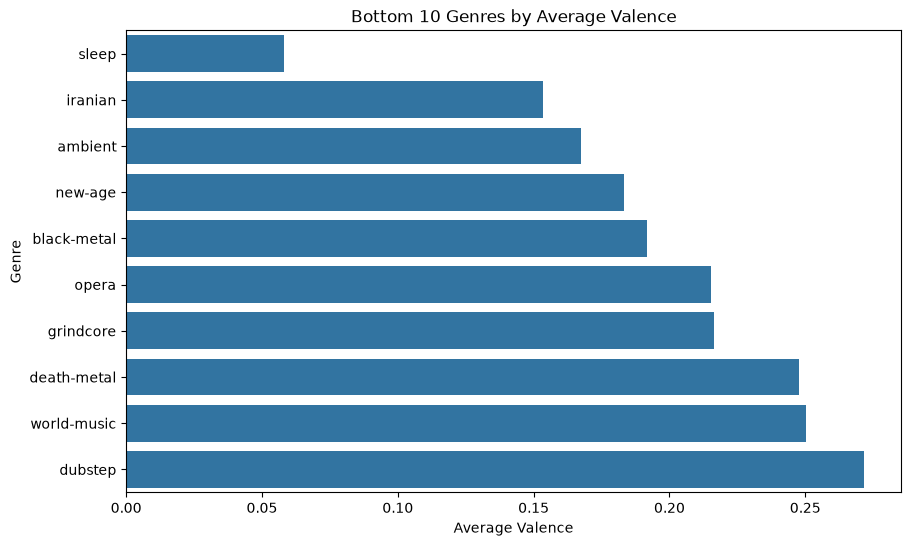

In [34]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=bottom_valence_genres.values,
    y=bottom_valence_genres.index
)

plt.title("Bottom 10 Genres by Average Valence")
plt.xlabel("Average Valence")
plt.ylabel("Genre")

plt.show()

## 8. Relationships between audio features

Do audio characteristics tend to vary together across tracks? The scatterplots compare energy with danceability and acousticness, and the correlation heatmap summarizes pairwise Pearson relationships. Pearson correlation captures linear association only.

In [35]:
df["energy"].corr(df["danceability"])

np.float64(0.13432548346897258)

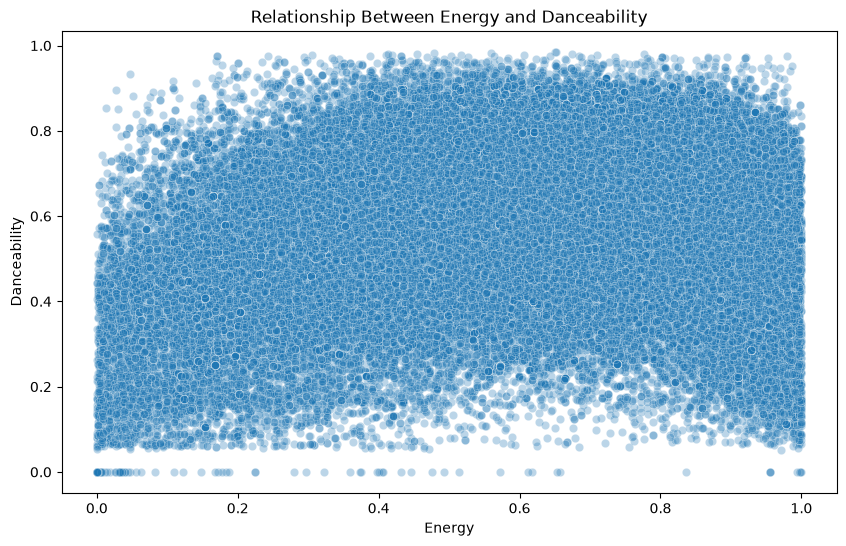

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="energy",
    y="danceability",
    alpha=0.3
)

plt.title("Relationship Between Energy and Danceability")
plt.xlabel("Energy")
plt.ylabel("Danceability")

plt.show()

In [37]:
df["energy"].corr(df["acousticness"])

np.float64(-0.7339063209687052)

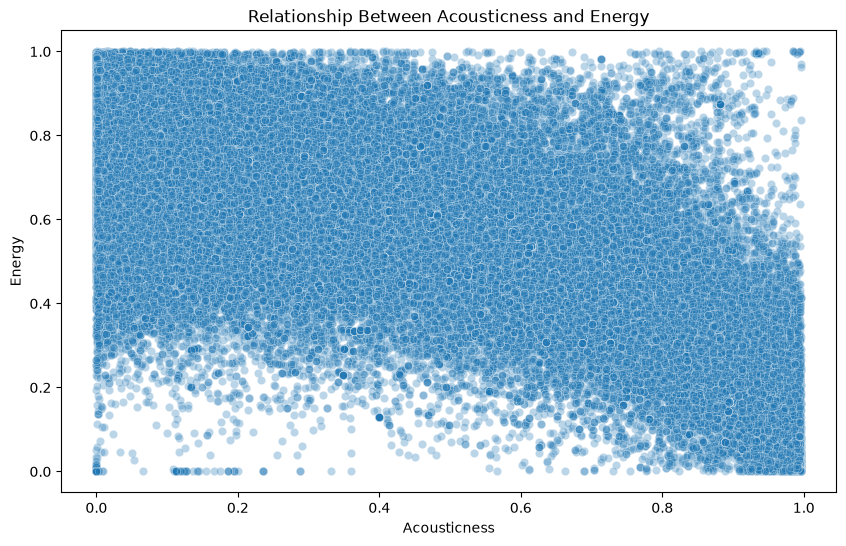

In [38]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="acousticness",
    y="energy",
    alpha=0.3
)

plt.title("Relationship Between Acousticness and Energy")
plt.xlabel("Acousticness")
plt.ylabel("Energy")

plt.show()

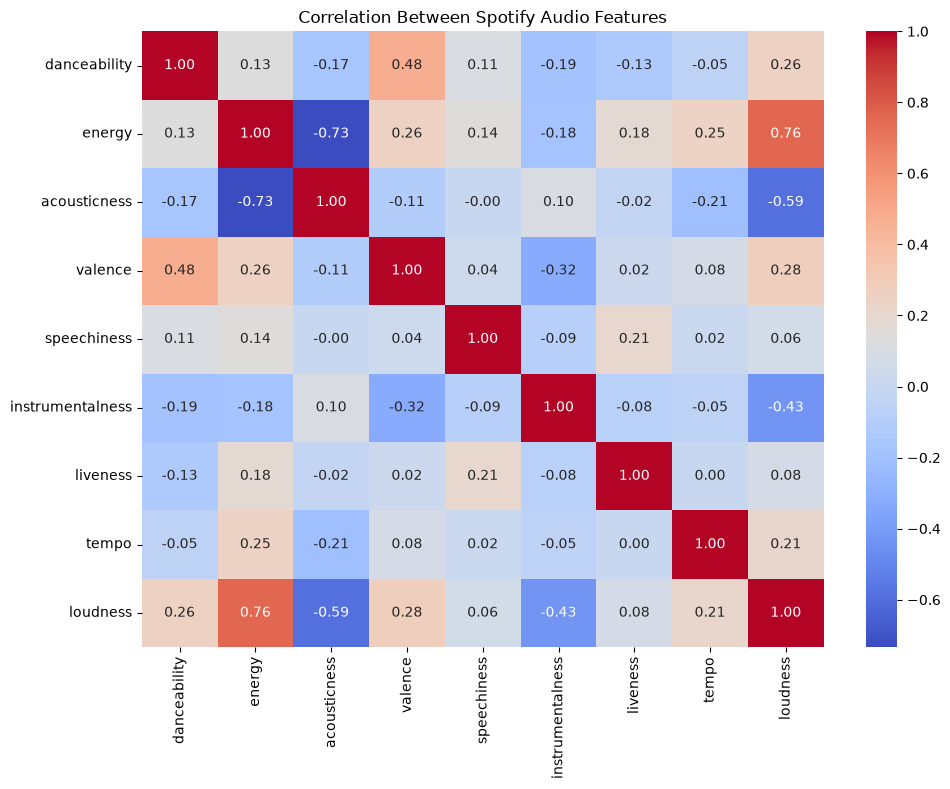

In [39]:
audio_features = [
    "danceability",
    "energy",
    "acousticness",
    "valence",
    "speechiness",
    "instrumentalness",
    "liveness",
    "tempo",
    "loudness"
]

correlation_matrix = df[audio_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Spotify Audio Features")

plt.show()

### Interpretation

Energy and loudness have a strong positive correlation (+0.76), while energy and acousticness have a strong negative correlation (-0.73). Danceability and valence have a moderate positive correlation (+0.48), while energy and danceability have a weak positive correlation (+0.13). These relationships describe linear patterns in this dataset and do not establish causation.

## 9. Audio features and popularity

Are individual audio features linearly associated with track popularity? Calculate Pearson correlations and plot the coefficients to compare their direction and strength. A correlation near zero means little linear association, not necessarily an absence of every possible relationship.

In [40]:
popularity_correlations = (
    df[
        [
            "popularity",
            "danceability",
            "energy",
            "acousticness",
            "valence",
            "speechiness",
            "instrumentalness",
            "liveness",
            "tempo",
            "loudness"
        ]
    ]
    .corr()["popularity"]
    .sort_values(ascending=False)
)

popularity_correlations

popularity          1.000000
loudness            0.050423
danceability        0.035448
tempo               0.013205
energy              0.001056
liveness           -0.005387
acousticness       -0.025472
valence            -0.040534
speechiness        -0.044927
instrumentalness   -0.095139
Name: popularity, dtype: float64

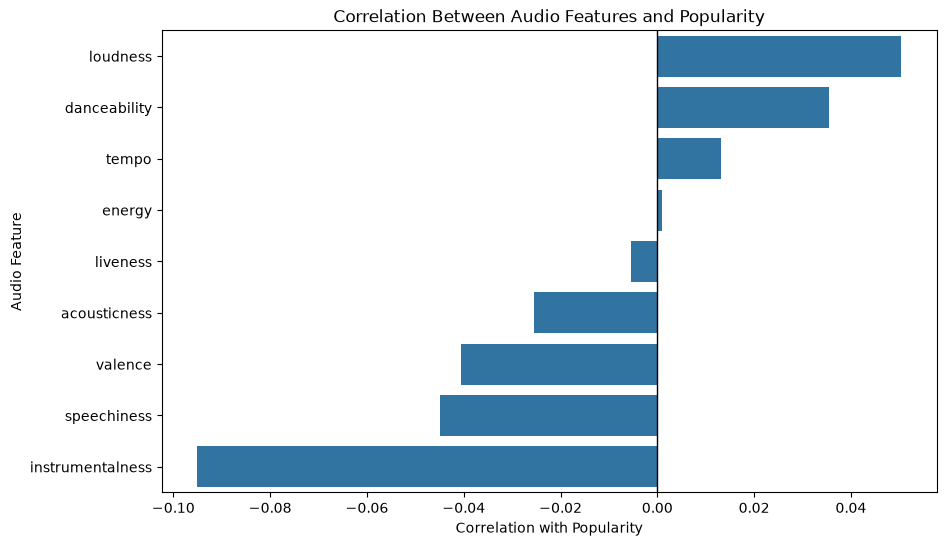

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=popularity_correlations.drop("popularity").values,
    y=popularity_correlations.drop("popularity").index
)

plt.axvline(x=0, color="black", linewidth=1)

plt.title("Correlation Between Audio Features and Popularity")
plt.xlabel("Correlation with Popularity")
plt.ylabel("Audio Feature")

plt.show()

### Interpretation

The chart shows that the selected audio features have very weak Pearson correlations with popularity. Loudness has the strongest positive correlation (+0.050), while instrumentalness has the strongest negative correlation (-0.095); energy, tempo, and liveness are close to zero. These individual linear associations explain little of the variation in popularity in this dataset. They do not establish that audio characteristics have no influence, since non-linear or combined relationships may exist.

## 10. Explicit vs non-explicit tracks

Do popularity scores differ between explicit and non-explicit tracks? Compare group counts, means, and medians, then use a boxplot to inspect how the score distributions overlap. This is an unadjusted descriptive comparison.

In [42]:
df.groupby("explicit")["popularity"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
explicit,,,
False,104253,32.937891,34.0
True,9747,36.454191,37.0


### Group comparison

Explicit tracks had a higher average popularity score (36.45) than non-explicit tracks (32.94), with median scores of 37 and 34, respectively. The groups were unequal in size: 9,747 explicit tracks and 104,253 non-explicit tracks. This is a difference observed in this dataset, not evidence that explicit content causes higher popularity; genre, artist popularity, and other factors may contribute.

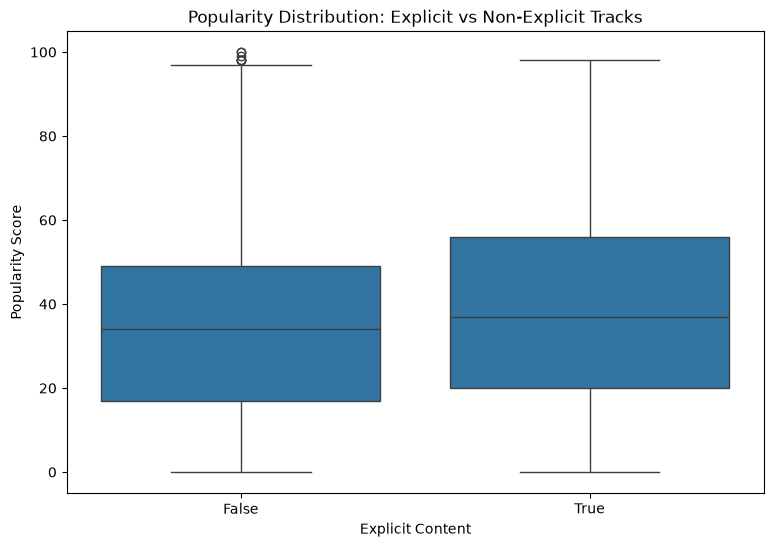

In [43]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="explicit",
    y="popularity"
)

plt.title("Popularity Distribution: Explicit vs Non-Explicit Tracks")
plt.xlabel("Explicit Content")
plt.ylabel("Popularity Score")

plt.show()

### Distribution comparison

The boxplot shows that explicit tracks have a higher median popularity score (37) than non-explicit tracks (34), consistent with the group summary. The distributions overlap considerably, and non-explicit tracks also include unusually high scores. Explicit status alone does not determine an individual track's popularity.

# **Final Findings and Conclusions**

## Project Overview

The aim of this project was to explore a dataset of approximately 114,000 Spotify tracks and investigate how musical characteristics differ across genres, how audio features relate to one another, and whether these characteristics are associated with track popularity.

Using Python, Pandas, Matplotlib and Seaborn, I explored the dataset, investigated patterns and created visualisations to make the findings easier to understand.

## Key Findings

### 1. Popularity varies considerably across tracks

The average popularity score was approximately 33.24, while the median was 35.

Around 14.05% of tracks had a popularity score of zero. This shows that a considerable portion of the dataset consisted of tracks with no recorded popularity score above zero.

Zero popularity scores were particularly common in some genres. Jazz had the highest proportion among genres at 68.1%, followed by Iranian at 65.6% and Romance at 63.6%.

### 2. Musical characteristics differ across genres

The analysis revealed noticeable differences in the average audio characteristics of different genres.

- Death metal had the highest average energy score (0.931), while classical had the lowest (0.190).
- Kids had the highest average danceability (0.779), while sleep had the lowest (0.168).
- Classical had the highest average acousticness (0.920), while death metal had the lowest (0.007).
- Salsa had the highest average valence (0.815), while sleep had the lowest (0.058).

These results demonstrate that genres can have quite different audio profiles.

### 3. Some audio characteristics are more closely related than others

The correlation analysis revealed several interesting relationships.

- Energy and loudness had a strong positive relationship (0.76). Higher-energy tracks tended to have higher loudness scores.
- Energy and acousticness had a strong negative relationship (-0.73). Higher-acousticness tracks tended to have lower energy scores.
- Danceability and valence had a moderate positive relationship (0.48).
- Energy and danceability had only a weak positive relationship (0.13).

This demonstrates that musical characteristics do not necessarily increase or decrease together.

### 4. Audio characteristics had very weak relationships with popularity

One of the more interesting findings was that the selected audio features had very weak linear relationships with popularity.

Loudness had the strongest positive correlation with popularity (0.050), while instrumentalness had the strongest negative correlation (-0.095).

Energy, danceability, tempo and the other investigated features also had correlations close to zero.

This suggests that the individual audio characteristics examined in this project do not, on their own, have strong linear relationships with popularity in this dataset.

### 5. Explicit tracks had higher average popularity scores

Explicit tracks had an average popularity score of 36.45, compared with 32.94 for non-explicit tracks.

Their median scores were also different: 37 for explicit tracks and 34 for non-explicit tracks.

This reveals a difference between the two groups within the dataset, but does not establish that explicit content causes higher popularity.

## Overall Conclusion

This analysis revealed that musical characteristics vary considerably across genres and that some audio features have stronger relationships with one another than others.

However, the investigation into popularity produced a different result: the selected audio features had very weak linear relationships with track popularity.

This suggests that musical characteristics alone may not explain why some tracks achieve higher popularity scores than others.

The project provided an opportunity to explore a real-world dataset, identify patterns, test assumptions and communicate findings through data analysis and visualisation.

Most importantly, the findings demonstrate the importance of examining evidence carefully rather than assuming that relationships exist simply because they seem intuitive.

## Limitations

- This dataset may not represent Spotify's entire catalogue, and it reflects a particular dataset snapshot.
- Popularity is a Spotify-specific score; it is not a universal measure of a track's success and may change over time.
- Pearson correlation captures linear relationships only. Correlation does not establish causation, and non-linear or combined relationships may be missed.
- Explicit and non-explicit group comparisons do not control for other influences such as genre or artist popularity; the groups also differ substantially in size.
- Initial inspection found one row with missing artist, album, and track names. The analysis is exploratory and does not apply a complete cleaning process; `Unnamed: 0` appears to be a redundant index.